# Penjelasan Dataset

Dataset ini berisi 38.765 data transaksi pembelian dari toko grocery yang digunakan untuk analisis Market Basket Analysis dan Association Rule Mining


| Column Name | Description |
| :--- | :--- |
| **Member_number** | ID customer yang melakukan transaksi |
| **Date** | Tanggal terjadinya transaksi pembelian. |
| **itemDescription** | Nama produk yang dibeli pelanggan.|

# Import Data

# Library Yang Digunakan

In [99]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kstest
from scipy.stats import probplot
import math

# Load Dataset

In [100]:
df=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Mini Project Analytical Intelligence & Optimization\Market Basket Analysis- Groceries_dataset(raw).csv") # Data disimpan di folder 'Mini Project' dengan nama 'Market Basket Analysis- Groceries_dataset(raw).csv'

# Data Exploration

# Menampilkan Data

In [101]:
df.head() # menampilkan 5 baris teratas atau pertama dari dataset

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


**df.info()** memberikan ringkasan struktur DataFrame, termasuk jumlah baris, kolom, tipe data, nilai non-null, dan penggunaan memori, membantu memahami data sebelum analisis.

In [102]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.6 MB


Hasil output:

- Dataset berisi 38765 baris dan 3 kolom
- Tidak terdapat missing values pada data
- Kolom Date perlu diubah menjadi tipe data ditetime

# Memperbaiki Tipe Data

In [103]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# Memeriksa Kembali

In [104]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Member_number    38765 non-null  int64         
 1   Date             38765 non-null  datetime64[us]
 2   itemDescription  38765 non-null  str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.3 MB


# Data Cleaning

# Memeriksa data kosong

In [105]:
pd.isnull(df).sum()

Member_number      0
Date               0
itemDescription    0
dtype: int64

Hasil Output: Tidak terdapat nilai kosong

# Memeriksa Data Duplikasi

In [106]:
# Menghitung total baris dan jumlah duplikasi
total_baris = len(df)
jumlah_duplikasi = df.duplicated().sum()

# Menghitung persentase duplikasi
persentasi_duplikasi = (
    jumlah_duplikasi / total_baris * 100
) if total_baris > 0 else 0

# Membuat tabel ringkasan
tabel_ringkasan = pd.DataFrame({
    'Keterangan': [
        'Total Keseluruhan Data',
        'Jumlah Duplikasi',
        'Persentase Duplikasi'
    ],
    'Nilai': [
        total_baris,
        jumlah_duplikasi,
        f"{persentasi_duplikasi:.2f}%"
    ]
})

# Menampilkan tabel
display(tabel_ringkasan)

,Keterangan,Nilai
0,Total Keseluruhan Data,38765
1,Jumlah Duplikasi,759
2,Persentase Duplikasi,1.96%


# Ringkasan Duplikasi di Tiap Kolom

In [107]:
# Ringkasan duplikasi setiap kolom
ringkasan_duplikasi = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Jumlah Duplikasi": [
        df[col].duplicated().sum()
        for col in df.columns
    ],
    "Jumlah Nilai Unik": [
        df[col].nunique()
        for col in df.columns
    ]
})

display(ringkasan_duplikasi)

,Nama Kolom,Jumlah Duplikasi,Jumlah Nilai Unik
0,Member_number,34867,3898
1,Date,38037,728
2,itemDescription,38598,167


# Memeriksa konsistensi data

In [108]:
# Mengatur agar isi kolom (terutama list unique values) tidak terpotong saat ditampilkan
pd.set_option('display.max_colwidth', None)

# Membuat list kosong untuk menampung informasi setiap kolom
list_info = []

# Melakukan iterasi pada setiap kolom di dataframe
for col in df.columns:
    list_info.append([
        col,                                # Nama kolom
        df[col].dtype,                 # Tipe data kolom
        df[col].nunique(),             # Jumlah nilai unik pada kolom
        list(df[col].unique())         # Daftar seluruh nilai unik pada kolom
    ])

# Mengubah list menjadi DataFrame agar lebih mudah dibaca
df_info = pd.DataFrame(
    columns=['column', 'dtype', 'n_unique', 'unique_values'],
    data=list_info
)

# Menampilkan ringkasan informasi kolom
display(df_info)

,column,dtype,n_unique,unique_values
0,Member_number,int64,3898,"[1808, 2552, 2300, 1187, 3037, 4941, 4501, 3803, 2762, 4119, 1340, 2193, 1997, 4546, 4736, 1959, 1974, 2421, 1513, 1905, 2810, 2867, 3962, 1088, 4976, 4056, 3611, 1420, 4286, 4918, 4783, 3709, 4289, 1559, 2900, 3527, 1495, 3558, 3128, 1863, 3841, 3903, 2658, 4272, 1120, 2676, 1697, 2507, 4620, 3365, 2978, 2910, 1061, 3276, 1326, 3023, 2185, 3552, 1967, 4708, 2874, 4177, 1663, 2632, 1377, 4162, 2270, 4829, 3811, 4766, 2436, 3860, 4875, 1587, 4038, 4750, 1199, 1603, 3111, 3894, 1456, 2022, 2505, 4851, 4293, 2775, 3693, 1202, 3699, 4152, 4155, 4010, 4389, 3746, 2560, 1503, 2555, 3645, 3886, 2932, ...]"
1,Date,datetime64[us],728,"[2015-07-21 00:00:00, 2015-01-05 00:00:00, 2015-09-19 00:00:00, 2015-12-12 00:00:00, 2015-02-01 00:00:00, 2015-02-14 00:00:00, 2015-05-08 00:00:00, 2015-12-23 00:00:00, 2015-03-20 00:00:00, 2015-02-12 00:00:00, 2015-02-24 00:00:00, 2015-04-14 00:00:00, 2015-09-03 00:00:00, 2015-03-30 00:00:00, 2015-05-03 00:00:00, 2015-09-02 00:00:00, 2015-08-03 00:00:00, 2015-07-07 00:00:00, 2015-09-08 00:00:00, 2015-11-12 00:00:00, 2015-09-18 00:00:00, 2015-11-30 00:00:00, 2015-07-17 00:00:00, 2015-06-12 00:00:00, 2015-02-13 00:00:00, 2015-01-14 00:00:00, 2015-03-08 00:00:00, 2015-01-27 00:00:00, 2015-10-22 00:00:00, 2015-10-26 00:00:00, 2015-10-08 00:00:00, 2015-10-03 00:00:00, 2015-04-11 00:00:00, 2015-02-21 00:00:00, 2015-09-29 00:00:00, 2015-01-09 00:00:00, 2015-04-03 00:00:00, 2015-04-20 00:00:00, 2015-08-04 00:00:00, 2015-07-19 00:00:00, 2015-10-06 00:00:00, 2015-10-16 00:00:00, 2015-06-06 00:00:00, 2015-09-26 00:00:00, 2015-08-15 00:00:00, 2015-05-21 00:00:00, 2015-08-25 00:00:00, 2015-03-11 00:00:00, 2015-06-05 00:00:00, 2015-07-28 00:00:00, 2015-09-05 00:00:00, 2015-06-19 00:00:00, 2015-10-11 00:00:00, 2015-06-16 00:00:00, 2015-01-20 00:00:00, 2015-02-15 00:00:00, 2015-04-13 00:00:00, 2015-02-07 00:00:00, 2015-03-02 00:00:00, 2015-03-14 00:00:00, 2015-12-22 00:00:00, 2015-07-01 00:00:00, 2015-11-03 00:00:00, 2015-04-12 00:00:00, 2015-05-05 00:00:00, 2015-05-12 00:00:00, 2015-07-08 00:00:00, 2015-09-21 00:00:00, 2015-12-10 00:00:00, 2015-09-30 00:00:00, 2015-01-31 00:00:00, 2015-12-13 00:00:00, 2015-03-04 00:00:00, 2015-12-20 00:00:00, 2015-11-06 00:00:00, 2015-02-18 00:00:00, 2015-07-22 00:00:00, 2015-08-23 00:00:00, 2015-04-15 00:00:00, 2015-01-26 00:00:00, 2015-12-29 00:00:00, 2015-10-20 00:00:00, 2015-08-17 00:00:00, 2015-05-17 00:00:00, 2015-07-25 00:00:00, 2015-09-11 00:00:00, 2015-06-18 00:00:00, 2015-12-08 00:00:00, 2015-04-25 00:00:00, 2015-05-14 00:00:00, 2015-05-04 00:00:00, 2015-10-10 00:00:00, 2015-06-11 00:00:00, 2015-10-30 00:00:00, 2015-05-23 00:00:00, 2015-11-07 00:00:00, 2015-09-04 00:00:00, 2015-05-18 00:00:00, 2015-03-26 00:00:00, 2015-06-23 00:00:00, ...]"
2,itemDescription,str,167,"[tropical fruit, whole milk, pip fruit, other vegetables, rolls/buns, pot plants, citrus fruit, beef, frankfurter, chicken, butter, fruit/vegetable juice, packaged fruit/vegetables, chocolate, specialty bar, butter milk, bottled water, yogurt, sausage, brown bread, hamburger meat, root vegetables, pork, pastry, canned beer, berries, coffee, misc. beverages, ham, turkey, curd cheese, red/blush wine, frozen potato products, flour, sugar, frozen meals, herbs, soda, detergent, grapes, processed cheese, fish, sparkling wine, newspapers, curd, pasta, popcorn, finished products, beverages, bottled beer, dessert, dog food, specialty chocolate, condensed milk, cleaner, white wine, meat, ice cream, hard cheese, cream cheese , liquor, pickled vegetables, liquor (appetizer), UHT-milk, candy, onions, hair spray, photo/film, domestic eggs, margarine, shopping bags, salt, oil, whipped/sour cream, frozen vegetables, sliced cheese, dish cleaner, baking powder, specialty cheese, salty snack, Instant food products, pet care, white bread, female sanitary products, cling film/bags, soap, frozen chicken, house keeping products, spread cheese, decalcifier, frozen dessert,

# Menghapus duplikasi data

In [109]:
df.drop_duplicates(inplace=True)

In [110]:
df.duplicated().sum()

np.int64(0)

# Data Preprocessing

# Feature Engineering

# Membuat Kolom Baru

In [111]:
# # Extract year, nama bulan, dan nama hari
# df['year'] = df['Date'].dt.year
# df['month'] = df['Date'].dt.month_name()
# df['day_name'] = df['Date'].dt.day_name()

# # Weekday: Monday-Friday
# df['weekday'] = df['Date'].dt.weekday < 5

# # Weekend: Saturday-Sunday
# df['weekend'] = df['Date'].dt.weekday >= 5

# # Pilih kolom yang ingin dipertahankan
# df = df[
#     ['Member_number', 'Date', 'year', 'month',
#      'day_name', 'weekday', 'weekend', 'itemDescription']
# ]

# df.head()

# Top 10 Products

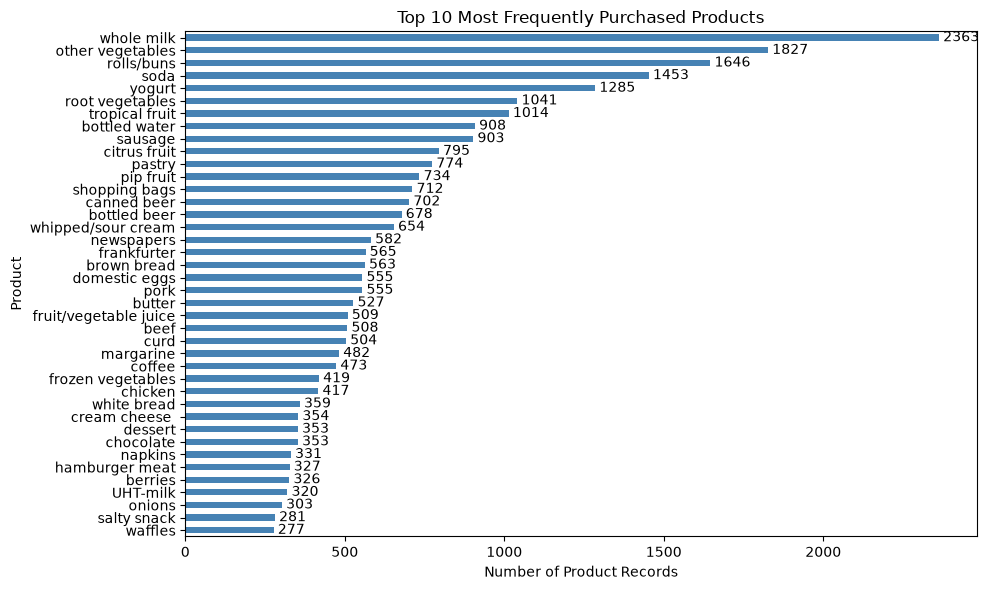

In [112]:
# Menghitung frekuensi kemunculan setiap produk
# value_counts() mengurutkan produk dari frekuensi tertinggi
top_products = df["itemDescription"].value_counts().head(40)

# Membuat bar chart horizontal agar nama produk mudah dibaca
ax = top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue"
)

# Menambahkan angka pada setiap batang untuk memudahkan perbandingan
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Top 10 Most Frequently Purchased Products")
plt.xlabel("Number of Product Records")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

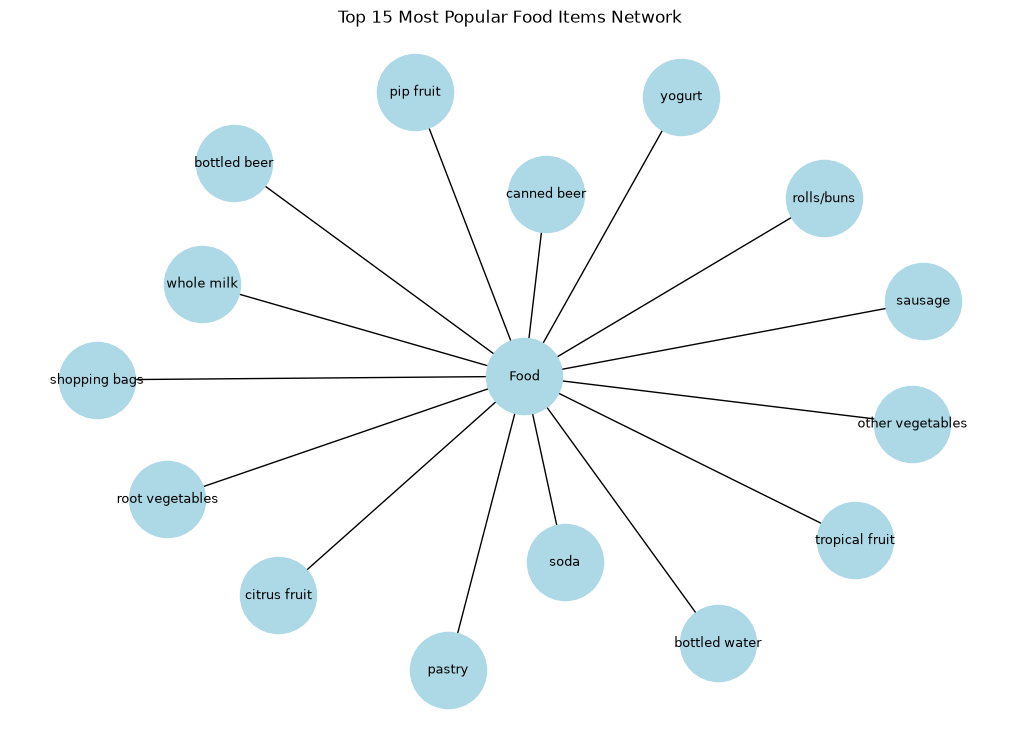

In [113]:
import networkx as nx
import matplotlib.pyplot as plt

# Ambil 15 item teratas
top_items = df['itemDescription'].value_counts().head(15).reset_index()
top_items.columns = ['item', 'count']

# Tambahkan node pusat
top_items['category'] = 'Food'

# Buat graph
G = nx.from_pandas_edgelist(
    top_items,
    source='category',
    target='item'
)

# Plot
plt.figure(figsize=(10,7))
pos = nx.spring_layout(G, k=0.5)

nx.draw(
    G, pos,
    with_labels=True,
    node_color='lightblue',
    node_size=3000,
    font_size=9
)

plt.title("Top 15 Most Popular Food Items Network")
plt.show()

# Getting the list of transactions
Dalam Market Basket Analysis, setiap transaksi pembelian harus memiliki identitas yang unik.
Pada dataset ini, satu member dapat melakukan pembelian beberapa item pada tanggal yang sama, dan setiap baris data merepresentasikan satu item. 
Oleh karena itu, dibuat kolom TransactionID dengan menggabungkan:
- Member_number
- Date

In [114]:
# Buat TransactionID
df['TransactionID'] = (
    df['Member_number'].astype(str) + "_" + df['Date'].astype(str)
)
df['TransactionID']

0        1808_2015-07-21
1        2552_2015-01-05
2        2300_2015-09-19
3        1187_2015-12-12
4        3037_2015-02-01
              ...       
38760    4471_2014-10-08
38761    2022_2014-02-23
38762    1097_2014-04-16
38763    1510_2014-12-03
38764    1521_2014-12-26
Name: TransactionID, Length: 38006, dtype: str

In [115]:
transactions = (
    df.groupby('TransactionID')['itemDescription']
    .apply(list)
    .tolist()
)
transactions

[['whole milk', 'pastry', 'salty snack'],
 ['sausage', 'whole milk', 'semi-finished bread', 'yogurt'],
 ['soda', 'pickled vegetables'],
 ['canned beer', 'misc. beverages'],
 ['sausage', 'hygiene articles'],
 ['sausage', 'whole milk', 'rolls/buns'],
 ['whole milk', 'soda'],
 ['frankfurter', 'soda', 'whipped/sour cream'],
 ['beef', 'white bread'],
 ['frankfurter', 'curd'],
 ['frozen vegetables', 'other vegetables'],
 ['butter', 'whole milk'],
 ['tropical fruit', 'sugar'],
 ['butter milk', 'specialty chocolate'],
 ['frozen meals', 'dental care'],
 ['rolls/buns'],
 ['root vegetables', 'detergent'],
 ['sausage', 'rolls/buns'],
 ['pip fruit', 'whole milk', 'tropical fruit'],
 ['dish cleaner', 'cling film/bags'],
 ['rolls/buns', 'red/blush wine', 'chocolate'],
 ['canned beer', 'frozen fish'],
 ['other vegetables', 'shopping bags'],
 ['root vegetables', 'whole milk', 'pastry'],
 ['whole milk', 'chocolate', 'packaged fruit/vegetables', 'rolls/buns'],
 ['other vegetables', 'hygiene articles'],
 

# Membuat basket size

Basket size analysis dilakukan untuk mengetahui jumlah rata-rata item yang dibeli dalam satu transaksi. Analisis ini membantu memahami perilaku belanja pelanggan serta mendukung strategi peningkatan penjualan melalui promosi bundling dan cross-selling.

In [116]:
# Hitung jumlah item per transaksi
basket_size_df = df.groupby('TransactionID')['itemDescription'].count().reset_index()

basket_size_df.columns = ['TransactionID', 'basket_size']

basket_size_df

,TransactionID,basket_size
0,1000_2014-06-24,3
1,1000_2015-03-15,4
2,1000_2015-05-27,2
3,1000_2015-07-24,2
4,1000_2015-11-25,2
...,...,...
14958,4999_2015-05-16,2
14959,4999_2015-12-26,2
14960,5000_2014-03-09,2
14961,5000_2014-11-16,2


In [117]:
df = df.merge(basket_size_df, on='TransactionID', how='left')
df

,Member_number,Date,itemDescription,TransactionID,basket_size
0,1808,2015-07-21,tropical fruit,1808_2015-07-21,3
1,2552,2015-01-05,whole milk,2552_2015-01-05,3
2,2300,2015-09-19,pip fruit,2300_2015-09-19,3
3,1187,2015-12-12,other vegetables,1187_2015-12-12,3
4,3037,2015-02-01,whole milk,3037_2015-02-01,3
...,...,...,...,...,...
38001,4471,2014-10-08,sliced cheese,4471_2014-10-08,3
38002,2022,2014-02-23,candy,2022_2014-02-23,3
38003,1097,2014-04-16,cake bar,1097_2014-04-16,3
38004,1510,2014-12-03,fruit/vegetable juice,1510_2014-12-03,3


# Distribusi Data

In [118]:
import numpy as np
import pandas as pd
from scipy.stats import kstest

# Pilih kolom numerik
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:

    # Standarisasi data menggunakan Z-score
    data_z = (df[col] - df[col].mean()) / df[col].std()

    # Hapus missing value dan nilai tak terhingga
    data_z = data_z.replace([np.inf, -np.inf], np.nan).dropna()

    # Lewati kolom yang tidak memiliki variasi
    if len(data_z) == 0 or data_z.std() == 0:
        print(f"Kolom: {col}")
        print("  Data kosong atau tidak memiliki variasi.\n")
        continue

    # Uji Kolmogorov-Smirnov
    stat, p = kstest(data_z, 'norm')

    print(f"Kolom: {col}")
    print(f"  Jumlah data    : {len(data_z)}")
    print(f"  Statistik uji  : {stat:.4f}")
    print(f"  p-value        : {p:.6f}")

    if p > 0.05:
        print("  ➜ Gagal menolak H0: data berdistribusi normal.\n")
    else:
        print("  ➜ Menolak H0: data tidak bedistribusi normal.\n")

Kolom: Member_number
  Jumlah data    : 38006
  Statistik uji  : 0.0595
  p-value        : 0.000000
  ➜ Menolak H0: data tidak bedistribusi normal.

Kolom: basket_size
  Jumlah data    : 38006
  Statistik uji  : 0.2821
  p-value        : 0.000000
  ➜ Menolak H0: data tidak bedistribusi normal.



# Visualisasi Distribusi Menggunakan Histogram dan Q-Q Plot

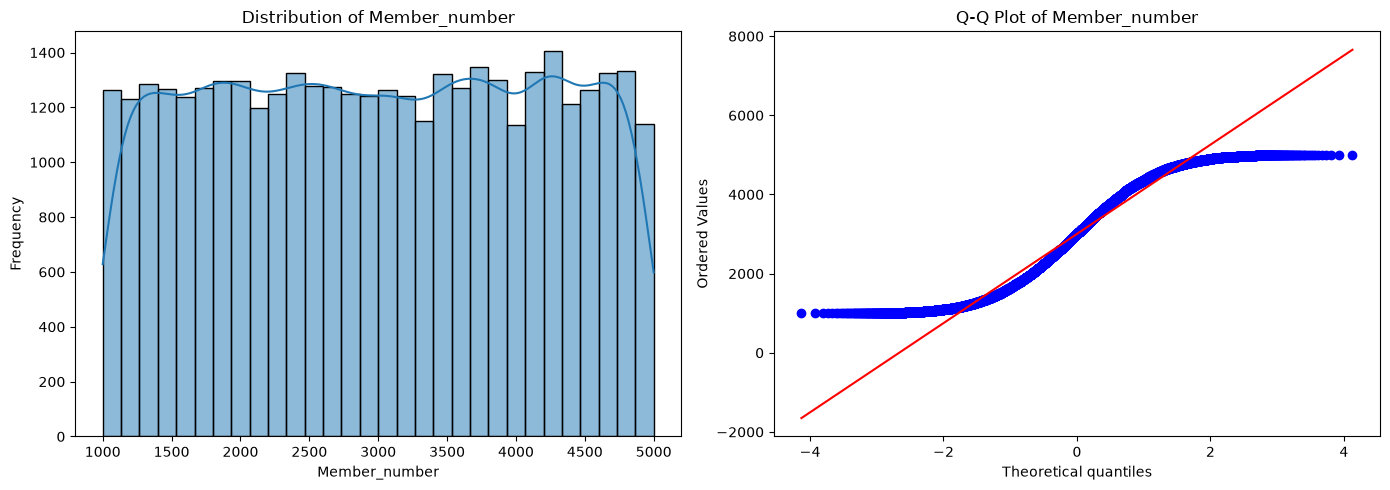

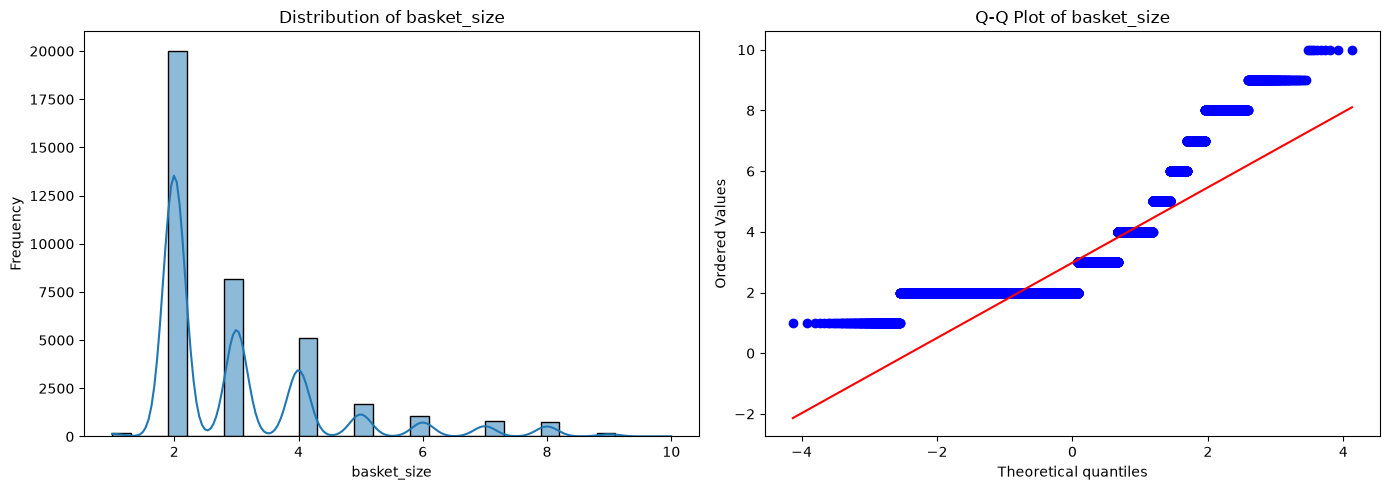

In [119]:
# Mengambil semua kolom numerik
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Membuat 2 chart per baris untuk setiap kolom numerik
for col in numeric_cols:

    # Menghapus nilai NaN
    data = df[col].dropna()

    # Membuat 2 subplot dalam 1 baris
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # HISTOGRAM
    sns.histplot(
        data,
        bins=30,
        kde=True,
        edgecolor='black',
        ax=axes[0]
    )
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')
    axes[0].set_title(f'Distribution of {col}')

    # Q-Q PLOT
    probplot(data, dist='norm', plot=axes[1])
    axes[1].set_title(f'Q-Q Plot of {col}')

    # Mengatur layout agar tidak bertumpuk
    plt.tight_layout()
    plt.show()

# Menampilkan Ringkasan Statistik

In [120]:
df.describe(include=['int64', 'float64'])

,Member_number,basket_size
count,38006.000000,38006.000000
mean,3003.361390,2.983161
std,1153.659151,1.458573
min,1000.000000,1.000000
25%,2001.000000,2.000000
50%,3005.000000,2.000000
75%,4007.000000,4.000000
max,5000.000000,10.000000


# Deteksi outlier menggunakan IQR

In [121]:
# Pilih semua kolom dengan tipe data integer
int_cols = df.select_dtypes(include=['int64', 'int32', 'float64']).columns

# Hitung Q1, Q3, dan IQR
q1 = df[int_cols].quantile(0.25)
q3 = df[int_cols].quantile(0.75)
iqr = q3 - q1

# Hitung batas bawah dan batas atas
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Buat mask untuk mendeteksi outlier
mask = (df[int_cols] < lower) | (df[int_cols] > upper)

# Ambil baris yang memiliki minimal satu outlier
outliers = df[mask.any(axis=1)]

# Tampilkan kolom integer yang mengandung outlier
outliers[int_cols]

,Member_number,basket_size
2103,3036,8
2104,2465,9
2106,1366,9
2107,3741,8
2108,2230,8
...,...,...
35591,3308,8
35592,1183,8
35593,1999,8
35595,3608,8


C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\HP\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


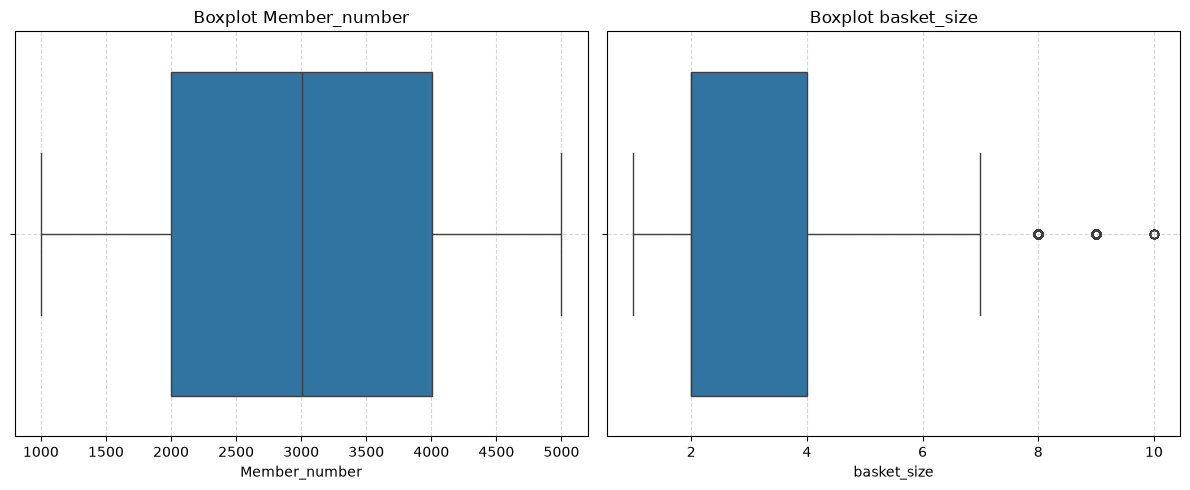

In [122]:
# Ambil semua kolom integer
int_cols = df.select_dtypes(include=['int64', 'int32', 'float64']).columns

# Tentukan jumlah kolom
n_cols = len(int_cols)

# Tentukan jumlah baris (2 plot per baris)
n_rows = math.ceil(n_cols / 2)

# Buat subplot
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5*n_rows))

# Ubah axes jadi 1D array supaya mudah di-loop
axes = axes.flatten()

# Loop untuk membuat boxplot tiap kolom
for i, col in enumerate(int_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot {col}')
    axes[i].grid(True, linestyle='--', alpha=0.5)

# Hapus subplot kosong jika jumlah kolom ganjil
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Penanganan Outlier:** Outlier dalam dataset ini dipertahankan karena hal tersebut adalah variasi perilaku transaksi dan bukan merupakan kesalahan data. Dengan demikian, analisis tetap merepresentasikan kondisi bisnis yang sebenarnya.

In [123]:
# Menggabungkan seluruh produk dari transaksi
flattened = [
    item
    for transaction in transactions
    for item in transaction
]

# Menghitung jumlah dan daftar produk unik
items = sorted(set(flattened))

print("Jumlah item unik:", len(items))
print("Daftar item:", items)

Jumlah item unik: 167
Daftar item: ['Instant food products', 'UHT-milk', 'abrasive cleaner', 'artif. sweetener', 'baby cosmetics', 'bags', 'baking powder', 'bathroom cleaner', 'beef', 'berries', 'beverages', 'bottled beer', 'bottled water', 'brandy', 'brown bread', 'butter', 'butter milk', 'cake bar', 'candles', 'candy', 'canned beer', 'canned fish', 'canned fruit', 'canned vegetables', 'cat food', 'cereals', 'chewing gum', 'chicken', 'chocolate', 'chocolate marshmallow', 'citrus fruit', 'cleaner', 'cling film/bags', 'cocoa drinks', 'coffee', 'condensed milk', 'cooking chocolate', 'cookware', 'cream', 'cream cheese ', 'curd', 'curd cheese', 'decalcifier', 'dental care', 'dessert', 'detergent', 'dish cleaner', 'dishes', 'dog food', 'domestic eggs', 'female sanitary products', 'finished products', 'fish', 'flour', 'flower (seeds)', 'flower soil/fertilizer', 'frankfurter', 'frozen chicken', 'frozen dessert', 'frozen fish', 'frozen fruits', 'frozen meals', 'frozen potato products', 'frozen

# One Hot Encoding

In [124]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

df_encoded = pd.DataFrame(te_array, columns=te.columns_)
df_encoded

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14958,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
14959,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14960,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14961,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [125]:
# Compute the support
support = df_encoded.mean()
support = pd.DataFrame(support, columns=['support']).sort_values('support', ascending=False)

# Print the support
support.head()

,support
whole milk,0.157923
other vegetables,0.122101
rolls/buns,0.110005
soda,0.097106
yogurt,0.085879


In [126]:
support.describe()

,support
count,167.000000
mean,0.015210
std,0.023381
min,0.000067
25%,0.002038
50%,0.005681
75%,0.017644
max,0.157923


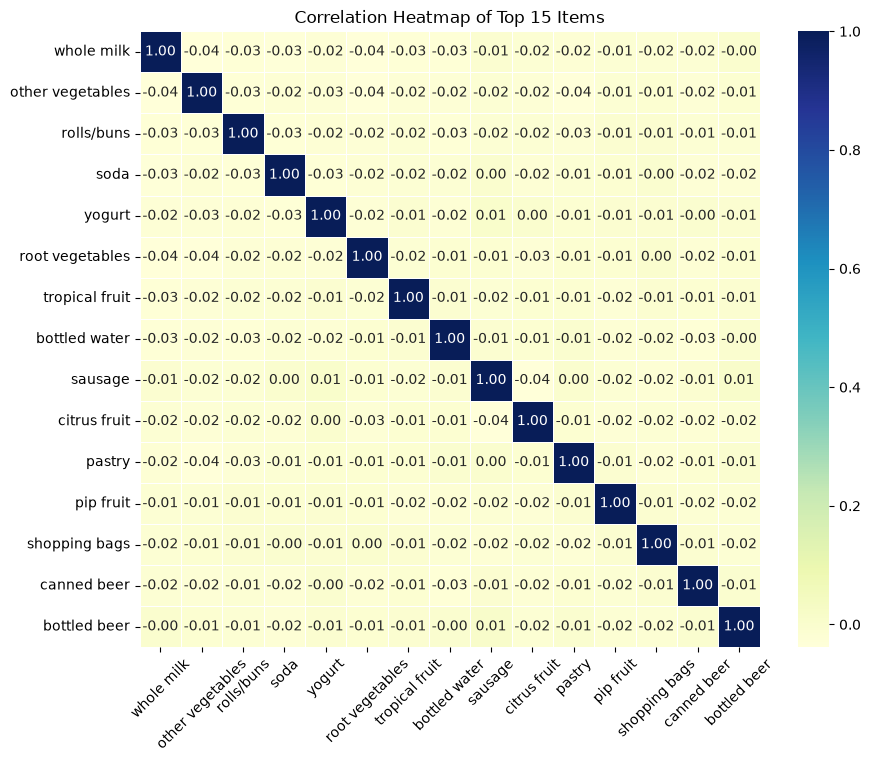

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung support dari one-hot encoded dataframe
support = df_encoded.mean().sort_values(ascending=False)

# Ambil 10 item dengan support tertinggi
top15_items = support.head(15).index

# Ambil matriks korelasi hanya untuk top 10
co_mtx = df_encoded[top15_items].corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(co_mtx,
            cmap="YlGnBu",
            annot=True,
            fmt=".2f",
            linewidths=0.5)

plt.title("Correlation Heatmap of Top 15 Items")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

# Apriori

In [128]:

from mlxtend.frequent_patterns import apriori

# 1. Menentukan minimum support
MIN_SUPPORT = 0.001  # 0.1%

# 2. Menjalankan algoritma Apriori
frequent_itemsets = apriori(
    df_encoded,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

# Urutkan berdasarkan support tertinggi
frequent_itemsets = frequent_itemsets.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

# 3. Memisahkan itemsets berdasarkan jumlah produk
frequent_1_itemsets = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) == 1
].copy().reset_index(drop=True)

frequent_2_itemsets = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) == 2
].copy().reset_index(drop=True)

frequent_3_itemsets = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) == 3
].copy().reset_index(drop=True)

frequent_4_itemsets = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) == 4
].copy().reset_index(drop=True)


# 4. Fungsi untuk membuat tabel tampilan
def format_itemsets(df_itemsets):
    df_display = df_itemsets.copy()

    # Mengubah frozenset menjadi teks
    df_display["itemsets"] = df_display["itemsets"].apply(
        lambda s: ", ".join(sorted(s))
    )

    # Mengubah support menjadi persen
    df_display["support"] = df_display["support"] * 100

    # Mengganti nama kolom
    df_display = df_display.rename(
        columns={"support": "support (%)"}
    )

    return df_display


# 5. Membuat tabel tampilan
frequent_1_display = format_itemsets(frequent_1_itemsets)
frequent_2_display = format_itemsets(frequent_2_itemsets)
frequent_3_display = format_itemsets(frequent_3_itemsets)
frequent_4_display = format_itemsets(frequent_4_itemsets)

# 6. Menampilkan jumlah hasil
print(f"Minimum support: {MIN_SUPPORT * 100:.2f}%")
print("Jumlah frequent 1-itemsets:", len(frequent_1_itemsets))
print("Jumlah frequent 2-itemsets:", len(frequent_2_itemsets))
print("Jumlah frequent 3-itemsets:", len(frequent_3_itemsets))
print("Jumlah frequent 4-itemsets:", len(frequent_4_itemsets))


# 7. Menampilkan hasil masing-masing itemsets
print("\nFrequent Itemsets — 1 Produk")
display(frequent_1_display.head(20))

print("\nFrequent Itemsets — 2 Produk")
display(frequent_2_display.head(20))

print("\nFrequent Itemsets — 3 Produk")
display(frequent_3_display.head(20))

print("\nFrequent Itemsets — 4 Produk")
display(frequent_4_display.head(20))


Minimum support: 0.10%
Jumlah frequent 1-itemsets: 149
Jumlah frequent 2-itemsets: 592
Jumlah frequent 3-itemsets: 9
Jumlah frequent 4-itemsets: 0

Frequent Itemsets — 1 Produk


,support (%),itemsets
0,15.792288,whole milk
1,12.210118,other vegetables
2,11.000468,rolls/buns
3,9.710620,soda
4,8.587850,yogurt
5,6.957161,root vegetables
6,6.776716,tropical fruit
7,6.068302,bottled water
8,6.034886,sausage
9,5.313106,citrus fruit



Frequent Itemsets — 2 Produk


,support (%),itemsets
0,1.483660,"other vegetables, whole milk"
1,1.396779,"rolls/buns, whole milk"
2,1.162868,"soda, whole milk"
3,1.116086,"whole milk, yogurt"
4,1.055938,"other vegetables, rolls/buns"
5,0.969057,"other vegetables, soda"
6,0.895542,"sausage, whole milk"
7,0.822028,"tropical fruit, whole milk"
8,0.808661,"other vegetables, yogurt"
9,0.808661,"rolls/buns, soda"



Frequent Itemsets — 3 Produk


,support (%),itemsets
0,0.147029,"sausage, whole milk, yogurt"
1,0.133663,"rolls/buns, whole milk, yogurt"
2,0.120297,"other vegetables, rolls/buns, whole milk"
3,0.113614,"other vegetables, whole milk, yogurt"
4,0.113614,"other vegetables, soda, whole milk"
5,0.113614,"rolls/buns, sausage, whole milk"
6,0.113614,"other vegetables, rolls/buns, soda"
7,0.106930,"sausage, soda, whole milk"
8,0.100247,"rolls/buns, soda, whole milk"



Frequent Itemsets — 4 Produk


,support (%),itemsets


# Membuat Association Rules

In [129]:
MIN_CONFIDENCE = 0.10

# Association rules memakai frequent_itemsets asli, jangan pakai itemsets_display
if frequent_itemsets["itemsets"].apply(len).ge(2).any():
    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=MIN_CONFIDENCE
    )
else:
    rules = pd.DataFrame()

print("Jumlah association rules:", len(rules))

Jumlah association rules: 130


In [130]:
if not rules.empty:
    rules_sorted = rules.sort_values(
        ["lift", "confidence", "support"],
        ascending=[False, False, False]
    ).copy()

    rules_display = rules_sorted[
        ["antecedents", "consequents", "support", "confidence", "lift",
         "leverage", "conviction"]
    ].copy()

    for col in ["antecedents", "consequents"]:
        rules_display[col] = rules_display[col].apply(
            lambda s: ", ".join(sorted(s))
        )

    display(rules_display.head(20))
else:
    print(
        "Belum ada rules. Periksa jumlah itemsets 2+; "
        "jika nol, uji min_support yang lebih rendah secara bertahap."
    )

,antecedents,consequents,support,confidence,lift,leverage,conviction
85,"whole milk, yogurt",sausage,0.001470,0.131737,2.182917,0.000797,1.082219
86,"sausage, whole milk",yogurt,0.001470,0.164179,1.911760,0.000701,1.093681
84,"sausage, yogurt",whole milk,0.001470,0.255814,1.619866,0.000563,1.131541
115,flour,tropical fruit,0.001069,0.109589,1.617141,0.000408,1.046969
119,processed cheese,root vegetables,0.001069,0.105263,1.513019,0.000363,1.039891
99,soft cheese,yogurt,0.001270,0.126667,1.474952,0.000409,1.046704
116,detergent,yogurt,0.001069,0.124031,1.444261,0.000329,1.043555
91,chewing gum,yogurt,0.001403,0.116667,1.358508,0.000370,1.034855
107,"rolls/buns, sausage",whole milk,0.001136,0.212500,1.345594,0.000292,1.069304
88,processed cheese,rolls/buns,0.001470,0.144737,1.315734,0.000353,1.040610


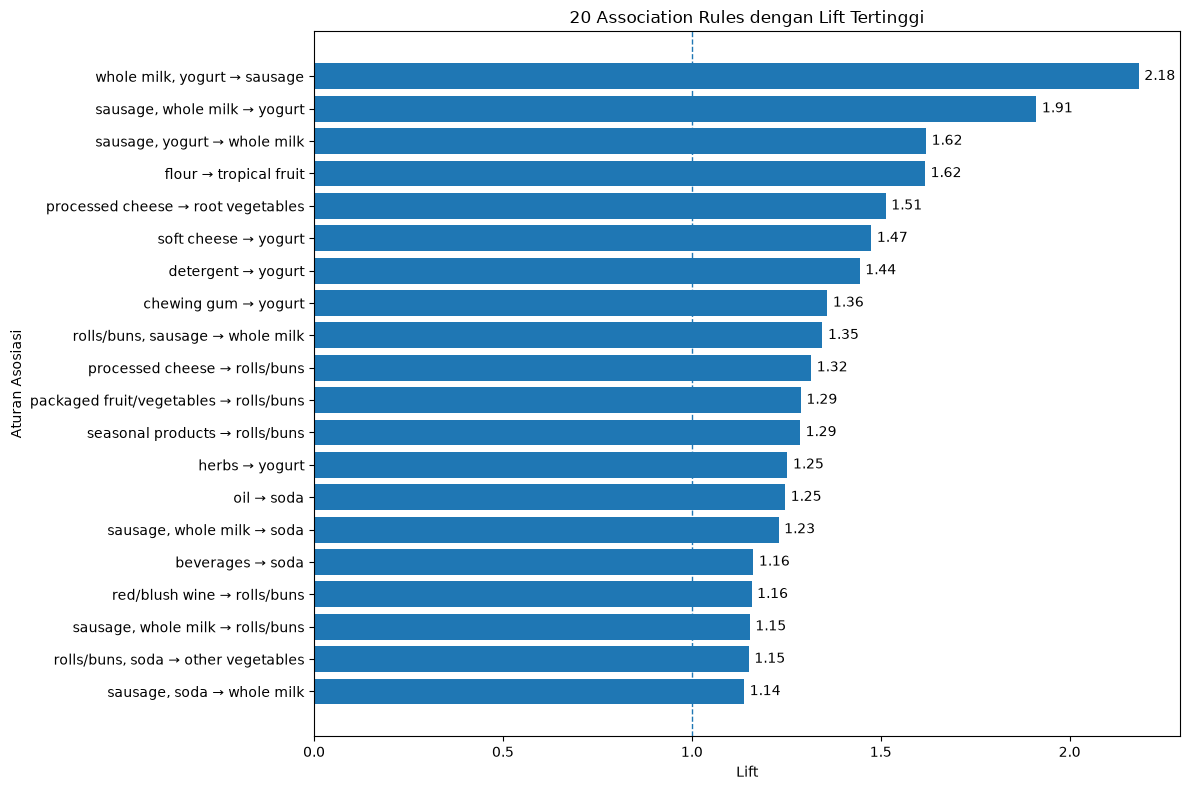

In [131]:

import matplotlib.pyplot as plt

if not rules.empty:
    rules_sorted = rules.sort_values(
        ["lift", "confidence", "support"],
        ascending=[False, False, False]
    ).copy()

    # Ambil 20 aturan teratas
    plot_rules = rules_sorted.head(20).copy()

    # Membuat label aturan
    plot_rules["rule"] = plot_rules.apply(
        lambda row: ", ".join(sorted(row["antecedents"]))
        + " → "
        + ", ".join(sorted(row["consequents"])),
        axis=1
    )

    # Urutkan ulang agar lift terbesar berada di atas
    plot_rules = plot_rules.sort_values("lift", ascending=True)

    plt.figure(figsize=(12, 8))
    bars = plt.barh(
        plot_rules["rule"],
        plot_rules["lift"]
    )

    plt.bar_label(bars, fmt="%.2f", padding=4)
    plt.axvline(1, linestyle="--", linewidth=1)

    plt.title("20 Association Rules dengan Lift Tertinggi")
    plt.xlabel("Lift")
    plt.ylabel("Aturan Asosiasi")
    plt.tight_layout()
    plt.show()

else:
    print("Belum ada rules untuk divisualisasikan.")


# Filter Item Dengan Confidence > 0.15 & Lift > 1.5

In [132]:
if not rules.empty:
    rules_filtered = rules[
        (rules["confidence"] > 0.15) &
        (rules["lift"] >= 1.5)
    ].copy()

    rules_filtered = rules_filtered.sort_values(
        ["lift", "confidence", "support"],
        ascending=[False, False, False]
    )

    print("Jumlah rules setelah filter:", len(rules_filtered))

    filtered_display = rules_filtered[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].copy()

    for col in ["antecedents", "consequents"]:
        filtered_display[col] = filtered_display[col].apply(
            lambda s: ", ".join(sorted(s))
        )

    display(filtered_display.head(20))
else:
    print("Tidak ada rules untuk difilter.")

Jumlah rules setelah filter: 2


,antecedents,consequents,support,confidence,lift
86,"sausage, whole milk",yogurt,0.00147,0.164179,1.911760
84,"sausage, yogurt",whole milk,0.00147,0.255814,1.619866


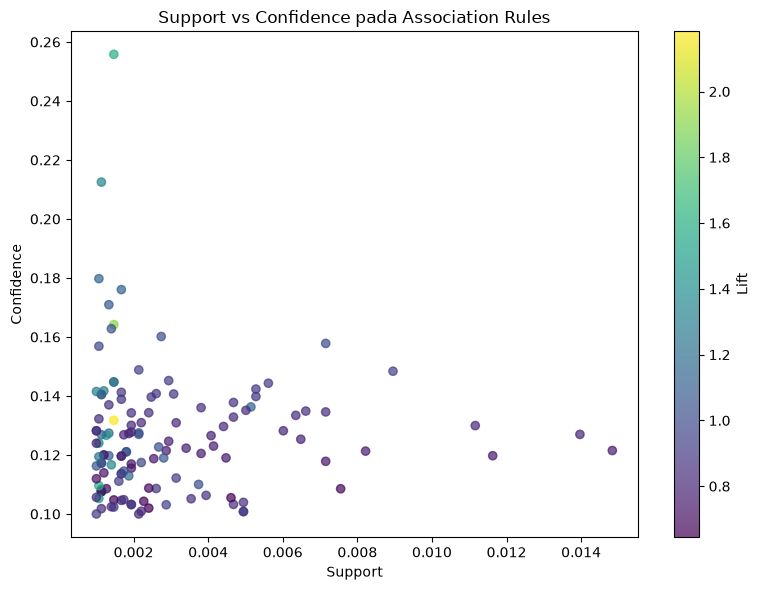

In [133]:
if not rules.empty:
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        rules["support"],
        rules["confidence"],
        c=rules["lift"],
        alpha=0.7
    )
    plt.colorbar(scatter, label="Lift")
    plt.title("Support vs Confidence pada Association Rules")
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.tight_layout()
    plt.show()
else:
    print("Visualisasi dilewati karena rules kosong.")

# Save File Dalam Bentuk Excel

In [136]:
import pandas as pd

# 1. Frequent itemsets untuk ekspor
itemsets_export = frequent_itemsets.copy()

itemsets_export["itemsets"] = itemsets_export["itemsets"].apply(
    lambda s: ", ".join(sorted(list(s)))
)

# Ubah support ke persen hanya pada file ekspor
itemsets_export["support"] = itemsets_export["support"] * 100
itemsets_export = itemsets_export.rename(
    columns={"support": "support (%)"}
)

itemsets_export.to_csv("frequent_itemsets_apriori.csv", index=False)
itemsets_export.to_excel("frequent_itemsets_apriori.xlsx", index=False)


# 2. Association rules untuk ekspor
if not rules.empty:
    rules_export = rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift",
            "leverage",
            "conviction"
        ]
    ].copy()

    # Ubah frozenset menjadi teks agar mudah dibaca di Excel
    for col in ["antecedents", "consequents"]:
        rules_export[col] = rules_export[col].apply(
            lambda s: ", ".join(sorted(list(s)))
        )

    # Ubah support dan confidence menjadi persen
    rules_export["support"] = rules_export["support"] * 100
    rules_export["confidence"] = rules_export["confidence"] * 100

    rules_export = rules_export.rename(
        columns={
            "support": "support (%)",
            "confidence": "confidence (%)"
        }
    )

    rules_export = rules_export.sort_values(
        ["lift", "confidence (%)"],
        ascending=[False, False]
    )

    rules_export.to_csv("association_rules_apriori.csv", index=False)
    rules_export.to_excel("association_rules_apriori.xlsx", index=False)

else:
    print("Tidak ada association rules untuk diekspor.")


# 3. Frekuensi produk
# Menghitung berapa banyak transaksi yang memuat setiap produk
product_frequency = (
    df.groupby("itemDescription")["TransactionID"]
      .nunique()
      .reset_index(name="frequency")
      .sort_values("frequency", ascending=False)
      .reset_index(drop=True)
)

product_frequency.to_csv("product_frequency.csv", index=False)
product_frequency.to_excel("product_frequency.xlsx", index=False)


# 4. Jumlah produk unik per transaksi
basket_size_df = (
    df.groupby("TransactionID")["itemDescription"]
      .nunique()
      .reset_index(name="basket_size")
)

basket_size_df.to_csv("basket_size_per_transaction.csv", index=False)
basket_size_df.to_excel("basket_size_per_transaction.xlsx", index=False)


# 5. Konfirmasi ekspor
print("Ekspor selesai. File berhasil disiapkan:")
print("- frequent_itemsets_apriori.csv / .xlsx")
print("- association_rules_apriori.csv / .xlsx")
print("- product_frequency.csv / .xlsx")
print("- basket_size_per_transaction.csv / .xlsx")

Ekspor selesai. File berhasil disiapkan:
- frequent_itemsets_apriori.csv / .xlsx
- association_rules_apriori.csv / .xlsx
- product_frequency.csv / .xlsx
- basket_size_per_transaction.csv / .xlsx
